# Multi-tabel — Ringkas Tabel Anak, Tempel ke Induk, lalu Klasifikasi
**Kapan dipakai:** data terdiri dari beberapa tabel yang dihubungkan kunci (ID).
Tabel **induk** = satu baris per hal yang ditebak (pinjaman, pelanggan). Tabel **anak** = banyak
baris per ID (transaksi, log, pesanan).

**Idenya:** model hanya bisa membaca satu tabel rata. Jadi tabel anak diringkas dulu per ID
(jumlah, rata-rata, minimum, terakhir, rasio), lalu tiap kolom ringkasan ditempel ke induk
dengan `.map` lewat ID.

**Langkah:**
1. Buang baris anak sesudah tanggal kejadian induk (supaya tidak bocor).
2. Ringkas tabel anak per ID, tempel ke induk.
3. Validasi silang, latih ulang, buat submission.

**Data demo:** Berka / PKDD'99 (bank Ceko). Induk = `loan` (682 pinjaman), anak = `trans`
(1 juta transaksi) dan `order` (perintah bayar tetap). Target `bad` = pinjaman macet.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/multitabel/berka"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/loan_train.csv"
TEST_CSV = f"{DATA_FOLDER}/loan_test.csv"
TRANS_CSV = f"{DATA_FOLDER}/trans.csv"
ORDER_CSV = f"{DATA_FOLDER}/order.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/loan_test_labels.csv"   # hanya ada di data latihan

ID_COL = "loan_id"
LINK_COL = "account_id"     # kunci yang menghubungkan induk dan anak
DATE_COL = "date"
TARGET = "bad"
PARENT_COLS = ["amount", "duration", "payments"]   # kolom asli induk
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV, parse_dates=[DATE_COL])
test = pd.read_csv(TEST_CSV, parse_dates=[DATE_COL])
trans = pd.read_csv(TRANS_CSV, low_memory=False, parse_dates=[DATE_COL])
order = pd.read_csv(ORDER_CSV)
print(train.shape, test.shape, trans.shape, order.shape)
print(train[TARGET].value_counts(normalize=True))
rows_per_account = trans.groupby(LINK_COL).size()
print("transaksi per rekening:")
print(rows_per_account.describe())

(511, 7) (171, 6) (1056320, 10) (6471, 6)
bad
0    0.888454
1    0.111546
Name: proportion, dtype: float64
transaksi per rekening:
count    4500.000000
mean      234.737778
std       126.849443
min         9.000000
25%       133.000000
50%       208.000000
75%       330.000000
max       675.000000
dtype: float64


## Langkah 1 — buang transaksi sesudah pinjaman cair
Transaksi setelah pinjaman termasuk cicilan yang gagal bayar = bocoran jawaban.
Train dan test digabung supaya feature dibuat sekali.

In [4]:
parents = pd.concat([train, test])
loan_dates = pd.Series(parents[DATE_COL].to_numpy(), index=parents[LINK_COL])
trans["loan_date"] = trans[LINK_COL].map(loan_dates)
trans = trans[trans[DATE_COL] < trans["loan_date"]]
trans = trans.sort_values(DATE_COL)
print("transaksi dipakai:", trans.shape)

transaksi dipakai: (54694, 11)


## Langkah 2a — ringkas tabel anak per rekening
`VYDAJ` = uang keluar, `PRIJEM` = uang masuk, `VYBER` = tarik tunai.

In [5]:
trans["money_out"] = trans["amount"].where(trans["type"] == "VYDAJ", 0)
trans["money_in"] = trans["amount"].where(trans["type"] == "PRIJEM", 0)
trans["is_cash"] = (trans["operation"] == "VYBER").astype(int)

per_account = trans.groupby(LINK_COL)
child = pd.DataFrame()
child["trans_count"] = per_account["amount"].count()
child["trans_mean"] = per_account["amount"].mean()
child["trans_max"] = per_account["amount"].max()
child["money_in_sum"] = per_account["money_in"].sum()
child["money_out_sum"] = per_account["money_out"].sum()
child["cash_share"] = per_account["is_cash"].mean()
child["balance_mean"] = per_account["balance"].mean()
child["balance_min"] = per_account["balance"].min()
child["balance_last"] = per_account["balance"].last()
days = (per_account[DATE_COL].max() - per_account[DATE_COL].min()).dt.days + 1
child["balance_trend"] = (child["balance_last"] - per_account["balance"].first()) / days
child["out_per_in"] = child["money_out_sum"] / child["money_in_sum"]

per_order = order.groupby(LINK_COL)
child["order_count"] = per_order["amount"].count()
child["order_sum"] = per_order["amount"].sum()
child.head()

,trans_count,trans_mean,trans_max,money_in_sum,money_out_sum,cash_share,balance_mean,balance_min,balance_last,balance_trend,out_per_in,order_count,order_sum
account_id,,,,,,,,,,,,,
2,54,7954.333333,30354,228687,153020,0.500000,32590.759259,1100,27855,86.585761,0.669124,2,10638.7
19,80,5856.350000,22708,242180,198020,0.425000,25197.137500,715,15854,40.145946,0.817656,1,2523.2
25,164,12113.981707,62900,1009156,910694,0.426829,62991.408537,900,31622,61.814889,0.902431,4,10614.2
37,116,7572.034483,47785,447360,389341,0.413793,39954.034483,-1011,16368,36.741093,0.870308,4,10305.5
38,55,4716.200000,20762,148404,105091,0.345455,31383.581818,13841,37417,91.365854,0.708141,4,9666.8


## Langkah 2b — tempel ke induk
Tiap kolom ringkasan dipetakan ke induk lewat `account_id`.

In [6]:
for name in child.columns:
    parents[name] = parents[LINK_COL].map(child[name])
parents["payment_per_balance"] = parents["payments"] / parents["balance_mean"]
parents["loan_per_balance"] = parents["amount"] / parents["balance_last"]
parents["loan_year"] = parents[DATE_COL].dt.year

all_features = parents.drop(columns=[ID_COL, LINK_COL, DATE_COL, TARGET])
X_all = all_features.iloc[:len(train)]
X_test_all = all_features.iloc[len(train):]
y = train[TARGET]
print("feature:", X_all.shape[1])

feature: 19


## Pilih feature (satu baris aktif)

In [7]:
feature_cols = list(X_all.columns)        # induk + ringkasan anak
# feature_cols = PARENT_COLS              # induk saja, untuk melihat manfaat tabel anak
X = X_all[feature_cols]
X_test = X_test_all[feature_cols]

## Langkah 3 — model + validasi silang
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

ROC-AUC CV: 0.9078
PR-AUC CV : 0.7805


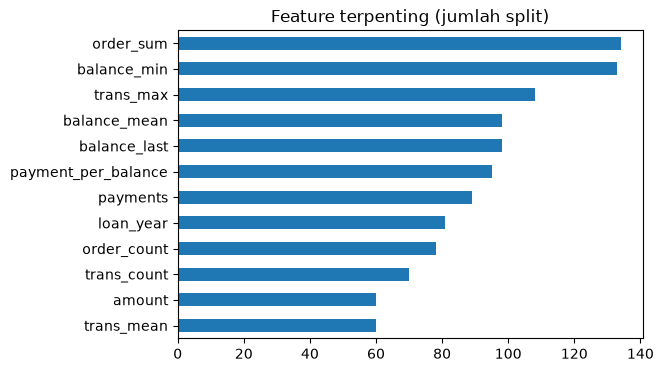

In [8]:
model = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=8, min_child_samples=10,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                       random_state=SEED, verbose=-1)

folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof_probabilities = cross_val_predict(model, X, y, cv=folds, method="predict_proba")
oof_scores = oof_probabilities[:, 1]
print("ROC-AUC CV:", round(roc_auc_score(y, oof_scores), 4))
print("PR-AUC CV :", round(average_precision_score(y, oof_scores), 4))

model.fit(X, y)
importance = pd.Series(model.feature_importances_, index=X.columns)
importance = importance.sort_values()
importance.tail(12).plot.barh(figsize=(6, 4))
plt.title("Feature terpenting (jumlah split)")
plt.show()

## Submission

In [9]:
probabilities = model.predict_proba(X_test)
predictions = probabilities[:, 1]           # peluang pinjaman macet

submission = pd.DataFrame()
submission["loan_id"] = test[ID_COL]
submission["bad"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,loan_id,bad
0,5665,0.001266
1,5343,0.004259
2,6810,0.004622
3,6659,0.004930
4,5241,0.002835


## Cek dengan kunci jawaban (HAPUS saat lomba)

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)
print("ROC-AUC test:", round(roc_auc_score(test_key[TARGET], predictions), 4))

ROC-AUC test: 0.9404
